# GetPop Reviews Sentiment Analysis

This notebook analyzes sentiment results from GetPop reviews using the TweetNLP model:
- **Model**: `cardiffnlp/twitter-roberta-base-sentiment-latest`
- **Citation**: Camacho-Collados et al. (2022) - TweetNLP: Cutting-Edge Natural Language Processing for Social Media

The model provides sentiment classification (positive, negative, neutral) with confidence scores.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Load Data

In [42]:
# Load sentiment analysis results
df = pd.read_csv('results/getpop_sentiment_reviews.csv')
df = df[df['verified']]

print(f"Total reviews: {len(df)}")
print(f"\nColumns: {df.columns.tolist()}")


Total reviews: 2927

Columns: ['Product', 'iced_level', 'sweet_level', 'rating', 'Sentiment', 'Sentiment Score', 'Site', 'Review', 'Product ID', 'Review ID', 'verified']


In [43]:
# 1. If sweet_level is not null AND iced_level is null -> set iced_level to 0
df.loc[df['sweet_level'].notna() & df['iced_level'].isna(), 'iced_level'] = 0

# 2. If iced_level is not null AND sweet_level is null -> set sweet_level to 0
df.loc[df['iced_level'].notna() & df['sweet_level'].isna(), 'sweet_level'] = 0
df.loc[df['iced_level'].notna(), 'iced_level'] += 1
df.loc[df['sweet_level'].notna(), 'sweet_level'] += 1
df.head()

,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified
0,raz-ca6000-alaskan-mint,5.0,5.0,1.0,neutral,0.593693,GETPOP,Way too sweet,1769,318,True
1,hyppe-max-flow-aloe-grape,4.0,4.0,5.0,positive,0.617023,GETPOP,Great flavor,1771,10175,True
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.0,neutral,0.397947,GETPOP,Perfect,1771,10174,True
3,hyppe-max-flow-aloe-grape,1.0,5.0,5.0,neutral,0.535714,GETPOP,Wonderful,1771,10173,True
4,hyde-edge-recharge-aloe-grape,3.0,3.0,4.0,neutral,0.538910,GETPOP,Nice smooth flavor,1773,10128,True


In [44]:
df['rating'].describe()

count    2927.000000
mean        4.768705
std         0.678851
min         1.000000
25%         5.000000
50%         5.000000
75%         5.000000
max         5.000000
Name: rating, dtype: float64

## Data Overview

In [45]:
# Basic statistics
print("Dataset Info:")
print(f"Total reviews: {len(df)}")
print(f"Unique products: {df['Product'].nunique()}")
print(f"Verified reviews: {df['verified'].sum()} ({df['verified'].sum()/len(df)*100:.1f}%)")
print(f"\nMissing values:")
print(df.isnull().sum())

Dataset Info:
Total reviews: 2927
Unique products: 1235
Verified reviews: 2927 (100.0%)

Missing values:
Product              0
iced_level         517
sweet_level        517
rating               0
Sentiment            0
Sentiment Score      0
Site                 0
Review               2
Product ID           0
Review ID            0
verified             0
dtype: int64


## Sentiment Distribution


Sentiment Distribution:
Sentiment
positive    1933
neutral      862
negative     132
Name: count, dtype: int64

Percentages:
Sentiment
positive    66.040314
neutral     29.449949
negative     4.509737
Name: proportion, dtype: float64


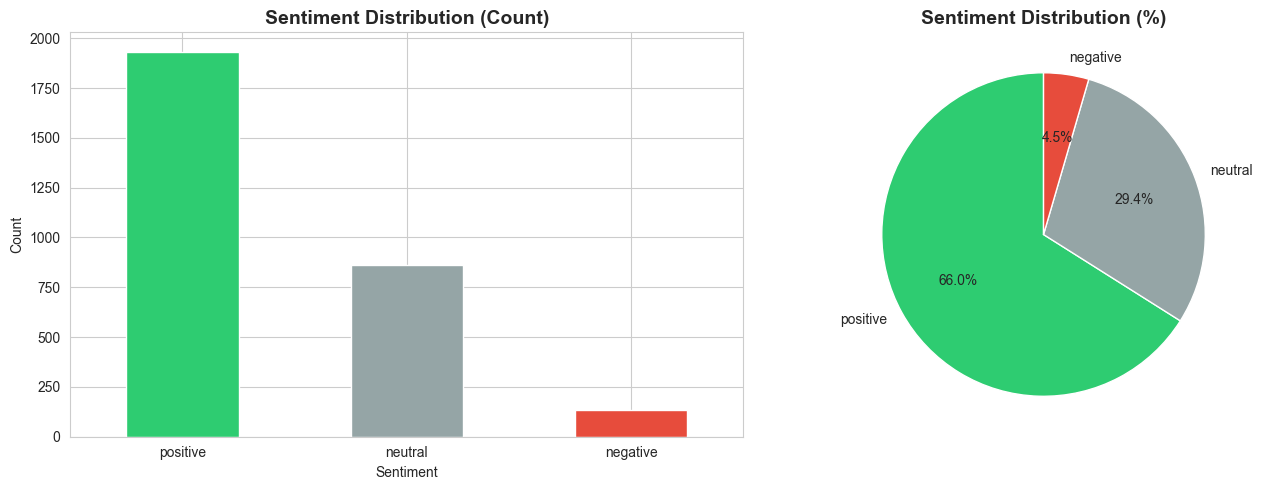

In [46]:
# Sentiment distribution
sentiment_counts = df['Sentiment'].value_counts()
print("\nSentiment Distribution:")
print(sentiment_counts)
print(f"\nPercentages:")
print(df['Sentiment'].value_counts(normalize=True) * 100)

# Plot sentiment distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
sentiment_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#95a5a6', '#e74c3c'])
axes[0].set_title('Sentiment Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
colors = ['#2ecc71' if s == 'positive' else '#95a5a6' if s == 'neutral' else '#e74c3c' 
          for s in sentiment_counts.index]
axes[1].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', 
            colors=colors, startangle=90)
axes[1].set_title('Sentiment Distribution (%)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## Sentiment Score Analysis


Sentiment Score Statistics by Class:
            count      mean       std       min       25%       50%       75%  \
Sentiment                                                                       
negative    132.0  0.734317  0.150933  0.408264  0.590626  0.771422  0.874350   
neutral     862.0  0.602699  0.110871  0.375587  0.515271  0.591798  0.679502   
positive   1933.0  0.820665  0.196133  0.378891  0.662087  0.936334  0.979197   

                max  
Sentiment            
negative   0.949755  
neutral    0.898230  
positive   0.990577  


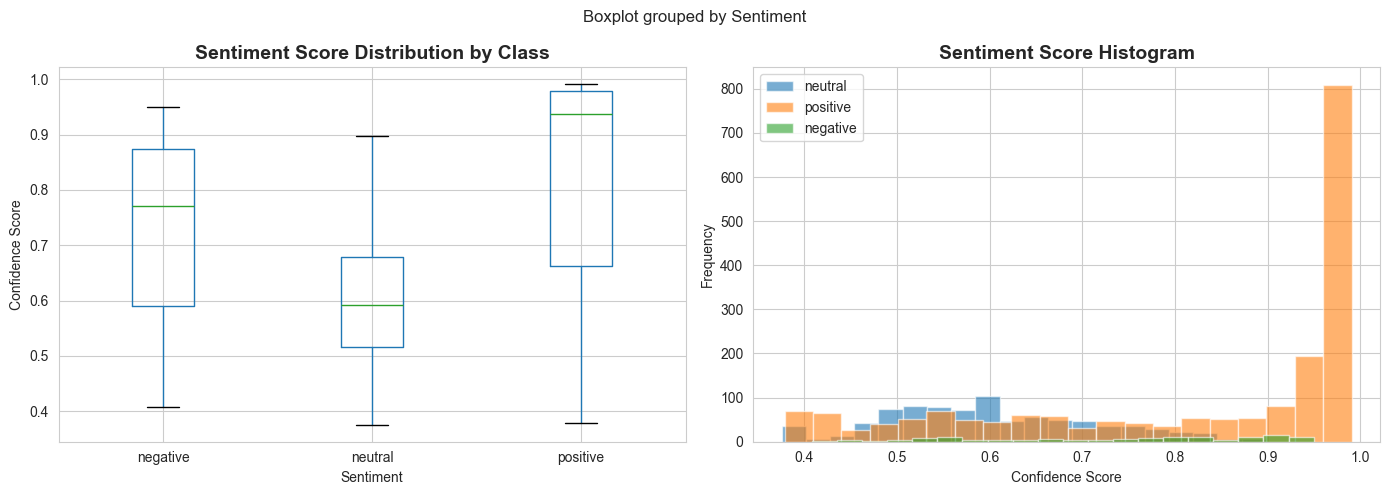

In [47]:
# Sentiment score statistics by sentiment class
print("\nSentiment Score Statistics by Class:")
print(df.groupby('Sentiment')['Sentiment Score'].describe())

# Plot sentiment score distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
df.boxplot(column='Sentiment Score', by='Sentiment', ax=axes[0])
axes[0].set_title('Sentiment Score Distribution by Class', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Confidence Score')
plt.sca(axes[0])
plt.xticks(rotation=0)

# Histogram by sentiment
for sentiment in df['Sentiment'].unique():
    data = df[df['Sentiment'] == sentiment]['Sentiment Score']
    axes[1].hist(data, alpha=0.6, bins=20, label=sentiment)
axes[1].set_title('Sentiment Score Histogram', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Confidence Score')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

## Sentiment vs Rating Correlation


Reviews with ratings: 2927 (100.0%)

Sentiment Distribution by Rating (%)
Sentiment   negative    neutral   positive
rating                                    
1.0        70.731707  24.390244   4.878049
2.0        53.333333  33.333333  13.333333
3.0        26.923077  37.179487  35.897436
4.0        13.108614  32.209738  54.681648
5.0         1.234568  28.952609  69.812824


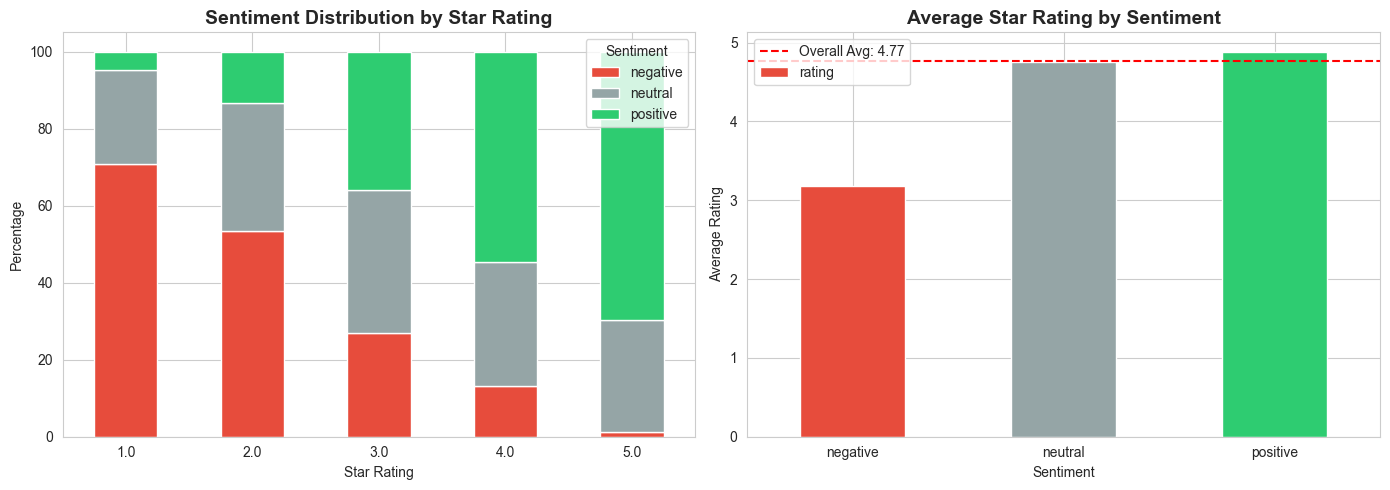

In [48]:
# Remove rows with missing ratings
df_with_rating = df.dropna(subset=['rating'])

print(f"\nReviews with ratings: {len(df_with_rating)} ({len(df_with_rating)/len(df)*100:.1f}%)")

# Sentiment by rating
sentiment_by_rating = pd.crosstab(df_with_rating['rating'], df_with_rating['Sentiment'], normalize='index') * 100
print("\nSentiment Distribution by Rating (%)")
print(sentiment_by_rating)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar chart
sentiment_by_rating.plot(kind='bar', stacked=True, ax=axes[0], 
                          color=['#e74c3c', '#95a5a6', '#2ecc71'])
axes[0].set_title('Sentiment Distribution by Star Rating', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Sentiment')

# Average rating by sentiment
avg_rating = df_with_rating.groupby('Sentiment')['rating'].mean()
avg_rating.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#95a5a6', '#2ecc71'])
axes[1].set_title('Average Star Rating by Sentiment', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Sentiment')
axes[1].set_ylabel('Average Rating')
axes[1].tick_params(axis='x', rotation=0)
axes[1].axhline(y=df_with_rating['rating'].mean(), color='red', linestyle='--', 
                label=f'Overall Avg: {df_with_rating["rating"].mean():.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()

## Sentiment Agreement Analysis

Check how well sentiment aligns with star ratings (5 stars = positive, 1-2 stars = negative)


Sentiment-Rating Agreement Rate: 67.41%


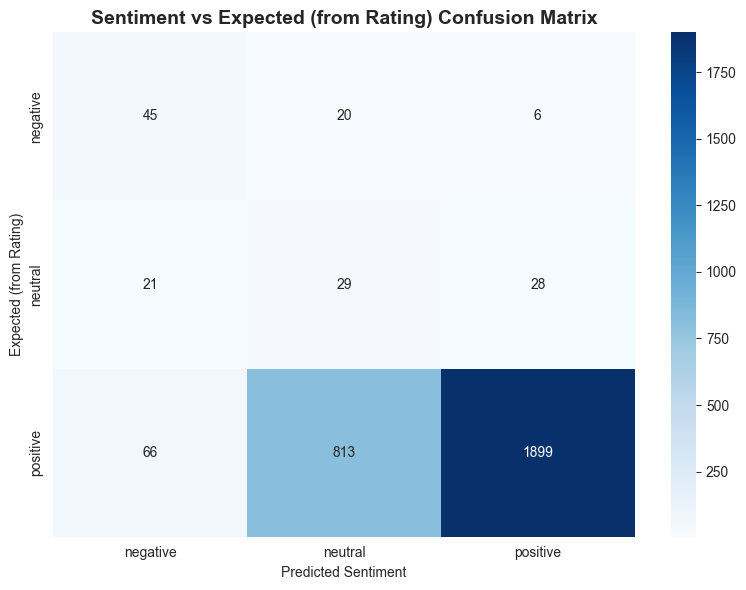


Classification Report:
              precision    recall  f1-score   support

    negative       0.34      0.63      0.44        71
     neutral       0.03      0.37      0.06        78
    positive       0.98      0.68      0.81      2778

    accuracy                           0.67      2927
   macro avg       0.45      0.56      0.44      2927
weighted avg       0.94      0.67      0.78      2927



In [49]:
# Define expected sentiment based on rating
def expected_sentiment(rating):
    if pd.isna(rating):
        return None
    elif rating >= 4:
        return 'positive'
    elif rating <= 2:
        return 'negative'
    else:
        return 'neutral'

df_with_rating['Expected Sentiment'] = df_with_rating['rating'].apply(expected_sentiment)
df_with_rating['Agreement'] = df_with_rating['Sentiment'] == df_with_rating['Expected Sentiment']

agreement_rate = df_with_rating['Agreement'].sum() / len(df_with_rating) * 100
print(f"\nSentiment-Rating Agreement Rate: {agreement_rate:.2f}%")

# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report

# Remove rows where expected sentiment is None
df_compare = df_with_rating.dropna(subset=['Expected Sentiment'])

cm = confusion_matrix(df_compare['Expected Sentiment'], df_compare['Sentiment'],
                     labels=['negative', 'neutral', 'positive'])

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative', 'neutral', 'positive'],
            yticklabels=['negative', 'neutral', 'positive'])
plt.title('Sentiment vs Expected (from Rating) Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Expected (from Rating)')
plt.xlabel('Predicted Sentiment')
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(df_compare['Expected Sentiment'], df_compare['Sentiment'],
                           labels=['negative', 'neutral', 'positive']))

## Flavor Profile Analysis


Reviews with iced level: 2410


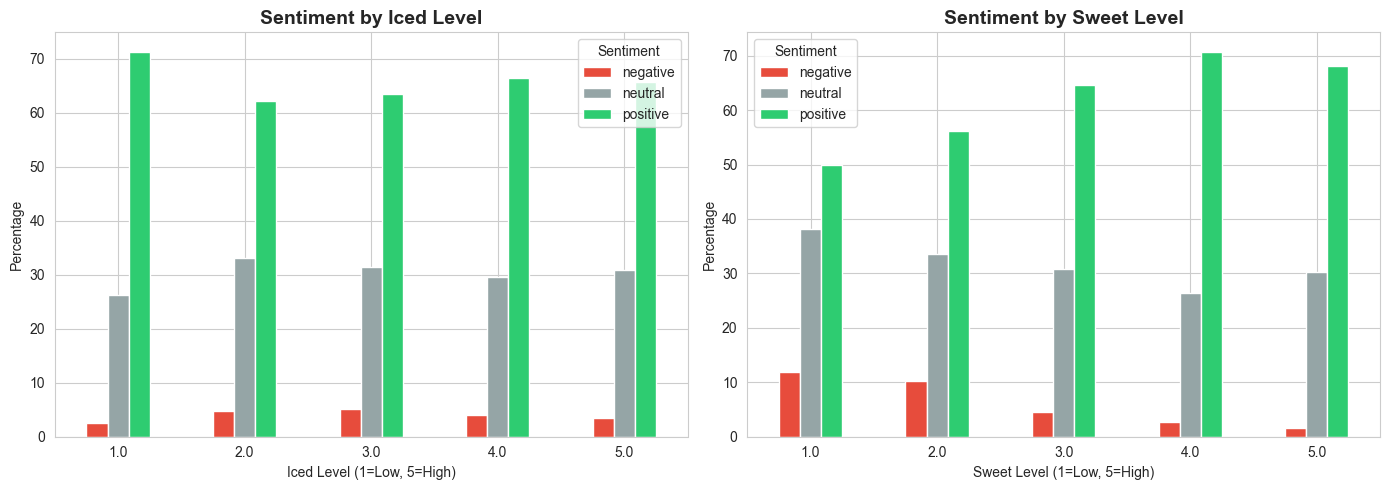

In [50]:
# Sentiment by iced level (coolness)
df_with_iced = df.dropna(subset=['iced_level'])
if len(df_with_iced) > 0:
    print(f"\nReviews with iced level: {len(df_with_iced)}")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Sentiment by iced level
    iced_sentiment = pd.crosstab(df_with_iced['iced_level'], df_with_iced['Sentiment'], normalize='index') * 100
    iced_sentiment.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#95a5a6', '#2ecc71'])
    axes[0].set_title('Sentiment by Iced Level', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Iced Level (1=Low, 5=High)')
    axes[0].set_ylabel('Percentage')
    axes[0].tick_params(axis='x', rotation=0)
    axes[0].legend(title='Sentiment')
    
    # Sentiment by sweet level
    df_with_sweet = df.dropna(subset=['sweet_level'])
    if len(df_with_sweet) > 0:
        sweet_sentiment = pd.crosstab(df_with_sweet['sweet_level'], df_with_sweet['Sentiment'], normalize='index') * 100
        sweet_sentiment.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#95a5a6', '#2ecc71'])
        axes[1].set_title('Sentiment by Sweet Level', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Sweet Level (1=Low, 5=High)')
        axes[1].set_ylabel('Percentage')
        axes[1].tick_params(axis='x', rotation=0)
        axes[1].legend(title='Sentiment')
    
    plt.tight_layout()
    plt.show()
else:
    print("No reviews with iced/sweet level data available")

## Top Products by Sentiment


Top 10 Products by Review Count:
Product
hqd-cuvie-plus-tobacco                       33
raz-ltx-25k-tobacco                          25
hyde-edge-recharge-minty-os                  21
hyde-edge-recharge-spearmint                 21
fifty-bar-20k-vanilla-custard                21
hqd-cuvie-plus-nuts-tobacco                  18
hyde-edge-recharge-peach-mango-watermelon    16
fume-extra-cuban-tobacco                     16
fume-infinity-plus-4500-cuban-tobacco        16
hyde-edge-recharge-blue-razz                 15
Name: count, dtype: int64

Top Products by Positive Sentiment %:
Product
hyde-edge-recharge-peach-mango-watermelon    81.250000
hyde-edge-recharge-minty-os                  76.190476
hyde-edge-recharge-spearmint                 76.190476
fume-infinity-plus-4500-cuban-tobacco        75.000000
hyde-edge-recharge-blue-razz                 73.333333
fume-extra-cuban-tobacco                     68.750000
fifty-bar-20k-vanilla-custard                66.666667
hqd-cuvie-plus-tobac

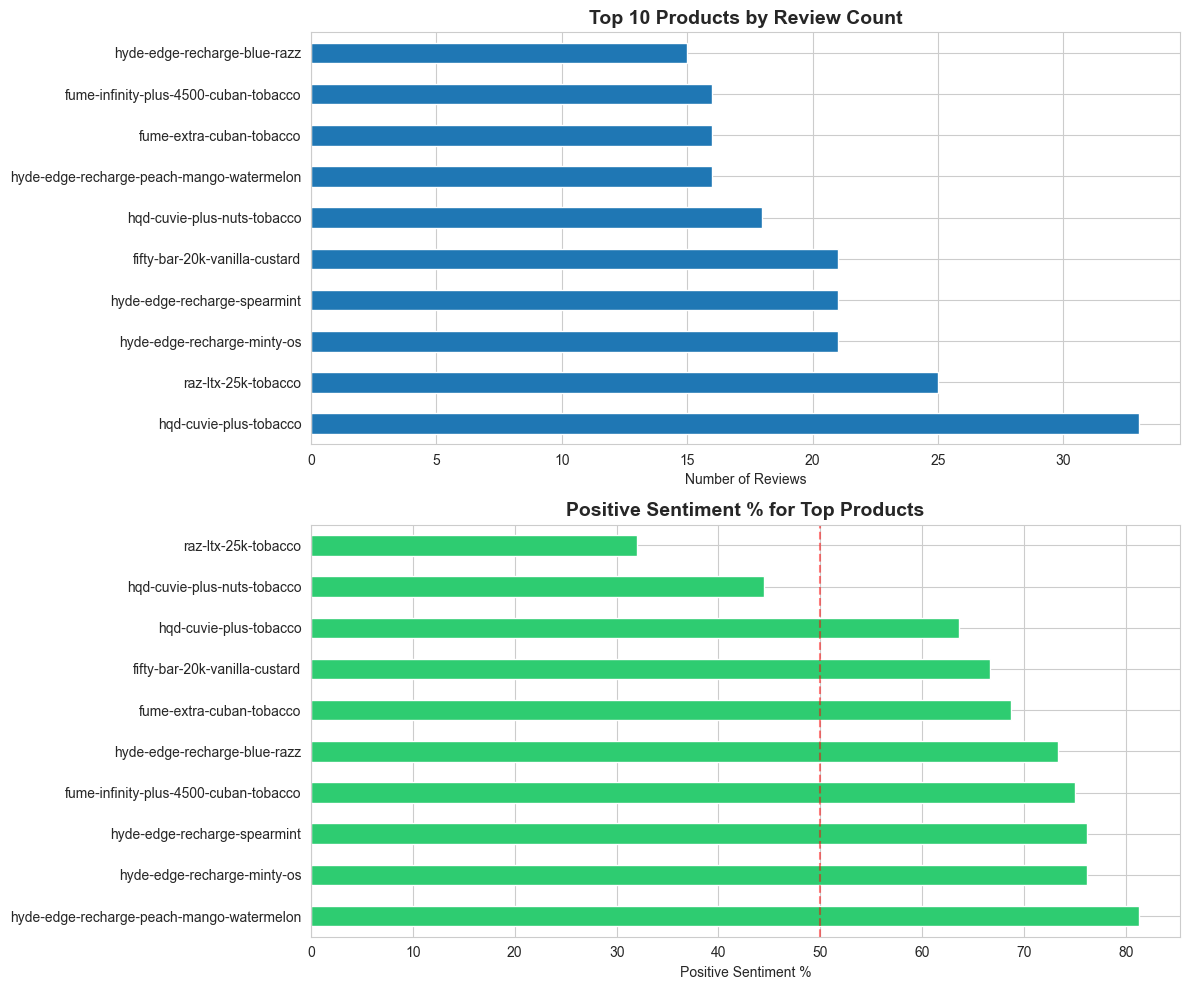

In [51]:
# Products with most reviews
product_counts = df['Product'].value_counts()
top_products = product_counts.head(10)

print("\nTop 10 Products by Review Count:")
print(top_products)

# Sentiment for top products
top_product_names = top_products.index
df_top = df[df['Product'].isin(top_product_names)]

# Calculate positive sentiment percentage for top products
product_sentiment = df_top.groupby('Product')['Sentiment'].apply(
    lambda x: (x == 'positive').sum() / len(x) * 100
).sort_values(ascending=False)

print("\nTop Products by Positive Sentiment %:")
print(product_sentiment)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Review count
top_products.plot(kind='barh', ax=axes[0])
axes[0].set_title('Top 10 Products by Review Count', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Reviews')
axes[0].set_ylabel('')

# Positive sentiment percentage
product_sentiment.plot(kind='barh', ax=axes[1], color='#2ecc71')
axes[1].set_title('Positive Sentiment % for Top Products', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Positive Sentiment %')
axes[1].set_ylabel('')
axes[1].axvline(x=50, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Misclassification Analysis

Examine cases where sentiment doesn't match the rating

In [52]:
# Show examples of disagreement
disagreements = df_with_rating[~df_with_rating['Agreement']].copy()

if len(disagreements) > 0:
    print(f"\nTotal disagreements: {len(disagreements)}")
    print("\nExamples of Sentiment-Rating Disagreements:")
    print("=" * 100)
    
    # High-rated but negative sentiment
    high_neg = disagreements[(disagreements['rating'] >= 4) & (disagreements['Sentiment'] == 'negative')]
    if len(high_neg) > 0:
        print("\n5-Star Reviews with NEGATIVE Sentiment:")
        for idx, row in high_neg.head(5).iterrows():
            print(f"\nRating: {row['rating']} | Sentiment: {row['Sentiment']} ({row['Sentiment Score']:.3f})")
            print(f"Review: {row['Review']}")
            print("-" * 100)
    
    # Low-rated but positive sentiment
    low_pos = disagreements[(disagreements['rating'] <= 2) & (disagreements['Sentiment'] == 'positive')]
    if len(low_pos) > 0:
        print("\n1-2 Star Reviews with POSITIVE Sentiment:")
        for idx, row in low_pos.head(5).iterrows():
            print(f"\nRating: {row['rating']} | Sentiment: {row['Sentiment']} ({row['Sentiment Score']:.3f})")
            print(f"Review: {row['Review']}")
            print("-" * 100)
else:
    print("No disagreements found (all sentiments match ratings)")


Total disagreements: 954

Examples of Sentiment-Rating Disagreements:

5-Star Reviews with NEGATIVE Sentiment:

Rating: 5.0 | Sentiment: negative (0.829)
Review: I can't my wife smokes them, I just know there getting hard to find.
----------------------------------------------------------------------------------------------------

Rating: 5.0 | Sentiment: negative (0.547)
Review: The vape is is the closest that I could find that tastes like a Newport 100 cigarette.
----------------------------------------------------------------------------------------------------

Rating: 4.0 | Sentiment: negative (0.645)
Review: Flavor is o k I wish you would get by my original black ice
----------------------------------------------------------------------------------------------------

Rating: 4.0 | Sentiment: negative (0.702)
Review: Not as strong as I've experienced but the flavor is hard to come by so beggars can't be choosers.
-------------------------------------------------------------------

## Verified vs Unverified Reviews


Sentiment Distribution: Verified vs Unverified (%)
Sentiment  negative    neutral   positive
verified                                 
True       4.509737  29.449949  66.040314


ValueError: The number of FixedLocator locations (1), usually from a call to set_ticks, does not match the number of labels (2).

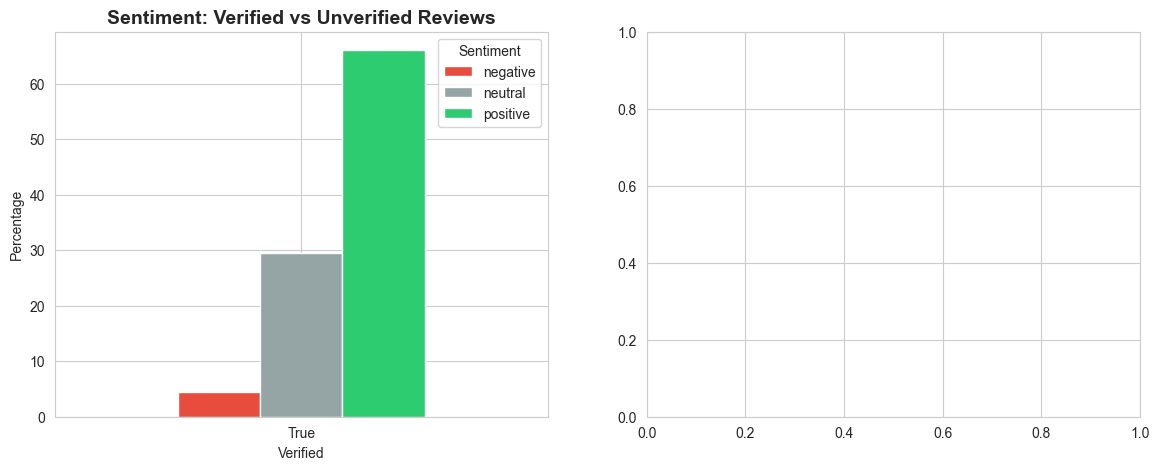

: 

In [ ]:
# Compare sentiment between verified and unverified reviews
verified_sentiment = pd.crosstab(df['verified'], df['Sentiment'], normalize='index') * 100

print("\nSentiment Distribution: Verified vs Unverified (%)")
print(verified_sentiment)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

verified_sentiment.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#95a5a6', '#2ecc71'])
axes[0].set_title('Sentiment: Verified vs Unverified Reviews', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Verified')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)
axes[0].set_xticklabels(['Unverified', 'Verified'])
axes[0].legend(title='Sentiment')

# Average sentiment score
avg_score = df.groupby('verified')['Sentiment Score'].mean()
avg_score.plot(kind='bar', ax=axes[1])
axes[1].set_title('Average Confidence Score: Verified vs Unverified', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Verified')
axes[1].set_ylabel('Average Confidence Score')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_xticklabels(['Unverified', 'Verified'])

plt.tight_layout()
plt.show()

## Summary Statistics

In [ ]:
print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

print(f"\nTotal Reviews Analyzed: {len(df):,}")
print(f"Unique Products: {df['Product'].nunique():,}")
print(f"Verified Reviews: {df['verified'].sum():,} ({df['verified'].sum()/len(df)*100:.1f}%)")

print("\nSentiment Breakdown:")
for sentiment in ['positive', 'neutral', 'negative']:
    count = (df['Sentiment'] == sentiment).sum()
    pct = count / len(df) * 100
    avg_score = df[df['Sentiment'] == sentiment]['Sentiment Score'].mean()
    print(f"  {sentiment.capitalize()}: {count:,} ({pct:.1f}%) - Avg confidence: {avg_score:.3f}")

if len(df_with_rating) > 0:
    print(f"\nRating Information:")
    print(f"  Reviews with ratings: {len(df_with_rating):,} ({len(df_with_rating)/len(df)*100:.1f}%)")
    print(f"  Average rating: {df_with_rating['rating'].mean():.2f}")
    print(f"  Sentiment-Rating agreement: {agreement_rate:.2f}%")

print(f"\nModel: cardiffnlp/twitter-roberta-base-sentiment-latest (TweetNLP)")
print(f"Citation: Camacho-Collados et al. (2022) - EMNLP System Demonstrations")


SUMMARY STATISTICS

Total Reviews Analyzed: 2,927
Unique Products: 1,235
Verified Reviews: 2,927 (100.0%)

Sentiment Breakdown:
  Positive: 1,933 (66.0%) - Avg confidence: 0.821
  Neutral: 862 (29.4%) - Avg confidence: 0.603
  Negative: 132 (4.5%) - Avg confidence: 0.734

Rating Information:
  Reviews with ratings: 2,927 (100.0%)
  Average rating: 4.77
  Sentiment-Rating agreement: 67.41%

Model: cardiffnlp/twitter-roberta-base-sentiment-latest (TweetNLP)
Citation: Camacho-Collados et al. (2022) - EMNLP System Demonstrations


## Export Results

In [ ]:
# Create summary by product
product_summary = df.groupby('Product').agg({
    'Review': 'count',
    'Sentiment Score': 'mean',
    'rating': 'mean',
    'verified': 'sum'
}).rename(columns={
    'Review': 'review_count',
    'Sentiment Score': 'avg_confidence',
    'rating': 'avg_rating',
    'verified': 'verified_count'
})

# Add sentiment counts
sentiment_counts_by_product = df.groupby(['Product', 'Sentiment']).size().unstack(fill_value=0)
product_summary = product_summary.join(sentiment_counts_by_product)

# Calculate positive percentage
if 'positive' in product_summary.columns:
    product_summary['positive_pct'] = (product_summary['positive'] / product_summary['review_count'] * 100).round(2)

product_summary = product_summary.sort_values('review_count', ascending=False)

print("\nProduct Summary (Top 15):")
print(product_summary.head(15))

# Save to CSV
output_path = 'results/getpop_sentiment_product_summary.csv'
product_summary.to_csv(output_path)
print(f"\nProduct summary saved to: {output_path}")